In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from google.colab import files

# Escolher uma rede de pathway

In [10]:
# 1. Fazer upload do arquivo
uploaded = files.upload()

# 2. Obter o nome do arquivo enviado
filename = next(iter(uploaded))

# 3. Ler a Edge List como uma rede NetworkX
G = nx.read_edgelist(filename)

# 4. Informações básicas da rede
print(f"Arquivo: {filename}")
print(f"Número de nós: {G.number_of_nodes()}")
print(f"Número de arestas: {G.number_of_edges()}")

Saving DNA Repair to DNA Repair (2)
Arquivo: DNA Repair (2)
Número de nós: 332
Número de arestas: 8353


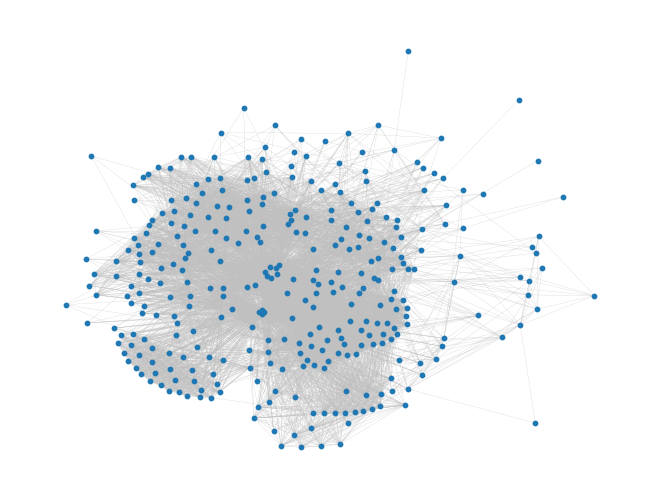

In [12]:
nx.draw_kamada_kawai(G,node_size=10,edge_color="silver",width=0.15)
plt.show()

# Abrindo o arquivo de drivers
Abra o arquivo "canonical_drivers.txt"

In [27]:
# 1. Fazer upload do arquivo
uploaded = files.upload()

# 2. Obter o nome do arquivo
filename = next(iter(uploaded))

# 3. Ler o arquivo
# header=None -> a primeira linha já é um dado, não o nome da coluna
df_genes = pd.read_csv(filename, header=None)

# 4. Transformar a coluna em uma lista
driversSet = set(df_genes[0])

# 5. Visualizar
print(f"\nQuantidade de genes: {len(driversSet)}")

#pegando apenas os drivers que não na rede
driversSet = driversSet & set(G.nodes())
print(f"\nQuantidade de genes que estão na rede: {len(driversSet)}")
print(f"Exemplo de 10 ")
print(list(driversSet)[:10])

Saving canonical_drivers.txt to canonical_drivers (4).txt

Quantidade de genes: 591

Quantidade de genes que estão na rede: 43
Exemplo de 10 
['MUTYH', 'XPC', 'RAD17', 'FANCG', 'MLH1', 'DDB2', 'ERCC5', 'XPA', 'BRIP1', 'MSH2']


# Analisando distribuição de centralidades

In [25]:
#Cria o conjunto de "não drivers", os vertices em azuis.
nonDrivers = set(G.nodes()) - driversSet
print("Tamanho dos não drivers", len(nonDrivers))
print("Tamanho dos drivers", len(driversSet))
print("Vertices na rede", G.number_of_nodes())

Tamanho dos não drivers 289
Tamanho dos drivers 43
Tamanho da rede 332


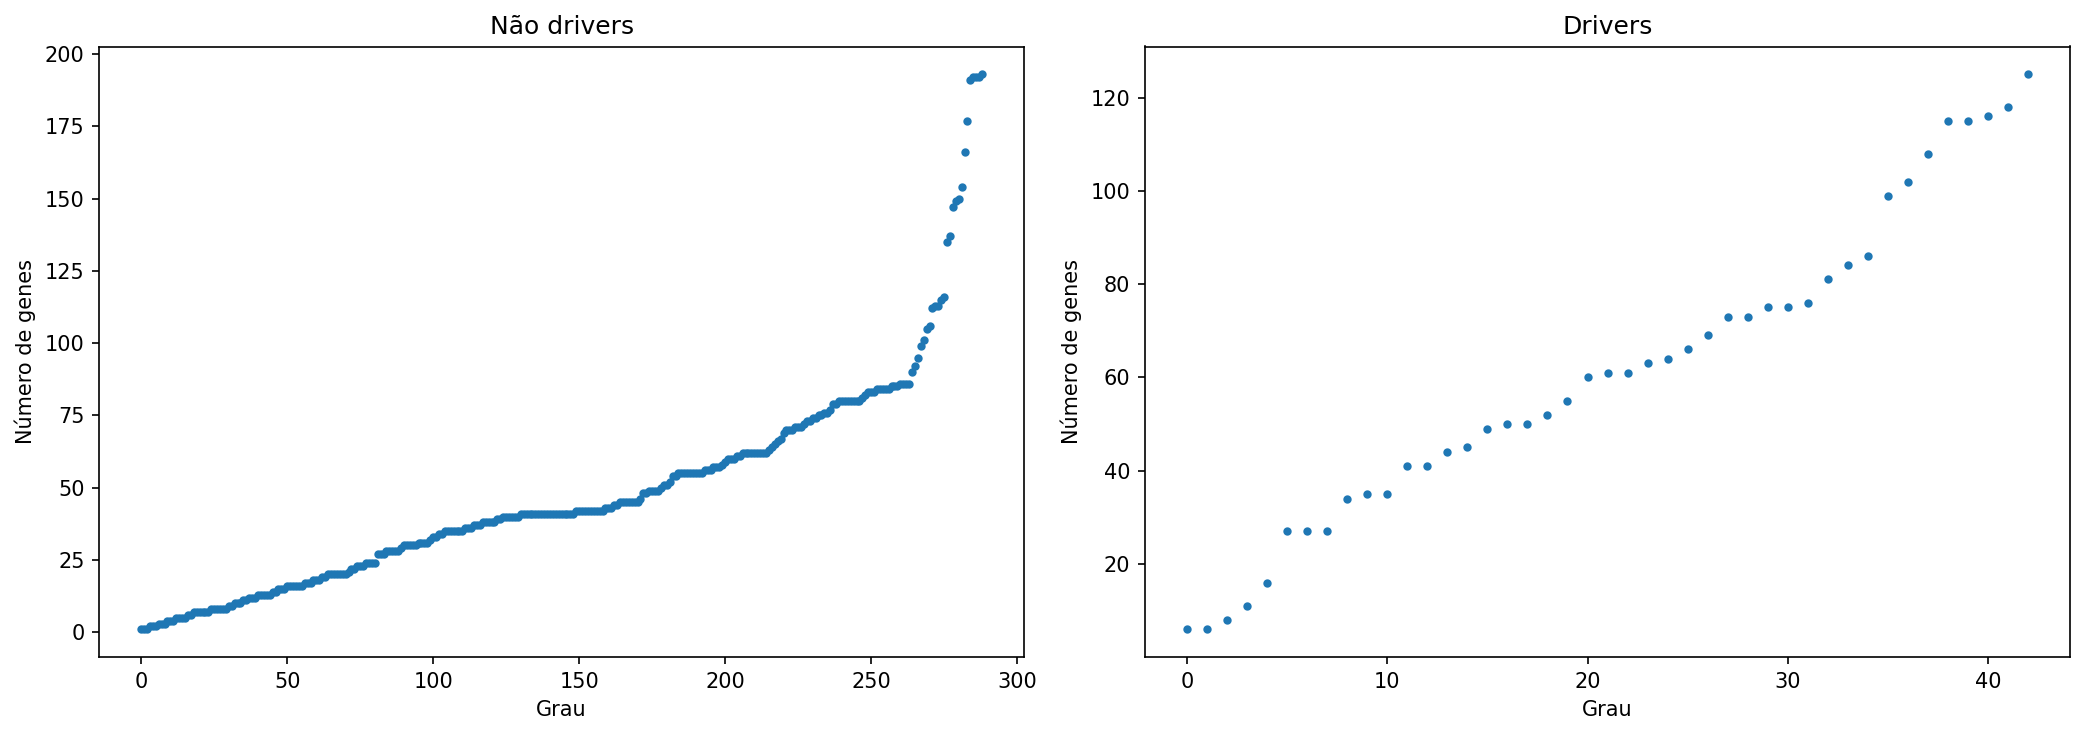

In [33]:
# Graus dos genes
degrees = dict(G.degree())

# Graus dos não drivers
degrees_nonDrivers = sorted([degrees[node] for node in nonDrivers])

# Graus dos drivers
degrees_drivers = sorted([degrees[node] for node in driversSet])


# Criar figura com 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# -------------------------
# Não drivers
# -------------------------
axes[0].plot(degrees_nonDrivers,'.')

axes[0].set_title('Não drivers')
axes[0].set_xlabel('Grau')
axes[0].set_ylabel('Número de genes')


# -------------------------
# Drivers
# -------------------------
axes[1].plot(degrees_drivers,'.')

axes[1].set_title('Drivers')
axes[1].set_xlabel('Grau')
axes[1].set_ylabel('Número de genes')


plt.tight_layout()
plt.show()